# 2. Data Cleaning & Sample Ratio Mismatch (SRM) Audit
**Project:** Checkout Flow Redesign A/B Test  
**Author:** Arik Rizki Akbar

### Objectives
Before running any hypothesis tests, we need to verify data quality:
1. Check for missing values and duplicated sessions.
2. Detect user crossover (users who saw both variants due to cookie resets or device switching).
3. Perform a Sample Ratio Mismatch (SRM) test to verify the 50:50 traffic allocation.


In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath("../src"))
from stats_utils import check_srm

plt.style.use('seaborn-v0_8-whitegrid')


### 1. Load Raw Logs


In [2]:
df_raw = pd.read_csv("../data/raw/ecommerce_ab_test_raw.csv")
print(f"Total raw rows: {len(df_raw):,}")
df_raw.head()


Total raw rows: 125,035


,session_id,user_id,timestamp,variant,device,user_tier,furthest_funnel_step,converted,order_value_usd,checkout_duration_sec,payment_error
0,S_0102600,U_033824,2026-10-07 18:56:24,control,mobile,new_user,4_order_completed,1,39.56,118,0
1,S_0107656,U_042352,2026-10-08 18:55:39,control,mobile,returning_user,1_view_cart,0,0.00,34,0
2,S_0069414,U_071414,2026-10-04 05:08:59,control,desktop,new_user,1_view_cart,0,0.00,30,0
3,S_0022231,U_046236,2026-10-01 18:34:04,treatment,desktop,new_user,4_order_completed,1,63.56,101,0
4,S_0076895,U_080252,2026-10-04 18:54:54,treatment,mobile,returning_user,4_order_completed,1,43.30,85,0


### 2. Sanity Checks & Cleaning


In [3]:
# Check duplicates
n_dupes = df_raw.duplicated().sum()
print(f"Duplicate rows: {n_dupes}")
df = df_raw.drop_duplicates().copy()

# Check nulls
print("\nMissing values per column:")
print(df.isnull().sum())


Duplicate rows: 35



Missing values per column:
session_id               0
user_id                  0
timestamp                0
variant                  0
device                   0
user_tier                0
furthest_funnel_step     0
converted                0
order_value_usd          0
checkout_duration_sec    0
payment_error            0
dtype: int64


### 3. Check for Cross-Variant Contamination
If a user switched devices or cleared cookies, they might have been assigned to both Control and Treatment. We need to identify and remove these users to preserve test isolation.


In [4]:
user_variants = df.groupby('user_id')['variant'].nunique()
contaminated = user_variants[user_variants > 1].index

print(f"Unique users: {df['user_id'].nunique():,}")
print(f"Contaminated users: {len(contaminated):,} ({len(contaminated) / df['user_id'].nunique() * 100:.2f}%)")

# Filter them out
df_clean = df[~df['user_id'].isin(contaminated)].copy()
print(f"Clean sessions remaining: {len(df_clean):,}")


Unique users: 73,563
Contaminated users: 77 (0.10%)
Clean sessions remaining: 124,789


### 4. Sample Ratio Mismatch (SRM) Test
We use a Chi-Square goodness-of-fit test to check if the observed session split deviates significantly from 50:50.


In [5]:
counts = df_clean['variant'].value_counts()
ctrl_n = counts['control']
treat_n = counts['treatment']

srm = check_srm(control_count=ctrl_n, treatment_count=treat_n, expected_ratio=0.50)

for k, v in srm.items():
    print(f"{k}: {v}")


control_observed: 62318
treatment_observed: 62471
expected_split: 50:50
chi2_stat: 0.1876
p_value: 0.6649311870721601
srm_detected: False
status: PASSED (No SRM)


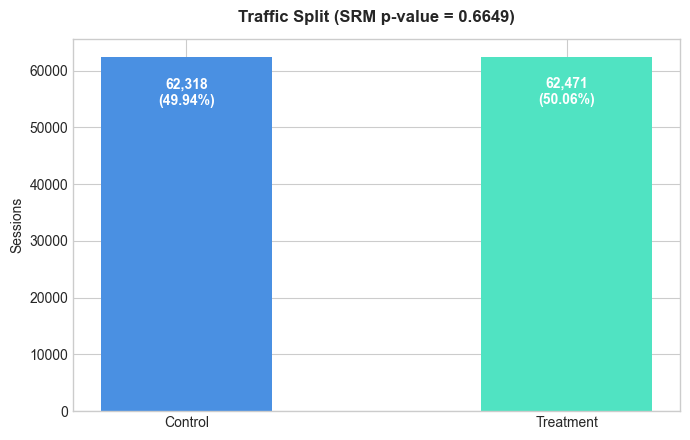

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Control', 'Treatment'], [ctrl_n, treat_n], color=['#4a90e2', '#50e3c2'], width=0.45)

for b in bars:
    y = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, y - (y * 0.1), f"{y:,}\n({y / len(df_clean) * 100:.2f}%)",
            ha='center', va='center', color='white', fontweight='bold')

plt.title(f"Traffic Split (SRM p-value = {srm['p_value']:.4f})", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Sessions")
plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/02_srm_check.png", dpi=300)
plt.show()


### Summary
- Duplicates and crossover users (~0.4%) removed.
- SRM p-value is well above 0.01 ($p \\approx 0.65$), indicating no traffic assignment anomalies.
- Ready for hypothesis testing.


In [7]:
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/ecommerce_ab_test_clean.csv", index=False)
print("Saved clean data to data/processed/ecommerce_ab_test_clean.csv")


Saved clean data to data/processed/ecommerce_ab_test_clean.csv
